### Step 1: Setup and Reproducability

In [51]:
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score)
from scipy.cluster.hierarchy import linkage, dendrogram

RANDOM_STATE=42
np.random.seed(RANDOM_STATE)
sns.set_theme(style='whitegrid')

### Step 2: Exploratory Data Analysis

Dataset data overview


,Item_Name,details,Catatory,price,priceWithCurrency,available,text,sold,lastUpdated,itemLocation
0,Dior,Christian Dior Sauvage Men's EDP 3.4 oz Fragra...,Eau de Parfum,84.99,US $84.99/ea,10.0,More than 10 available / 116 sold,NaN,"May 24, 2024 10:03:04 PDT","Allen Park, Michigan, United States"
1,AS SHOW,A-v-entus Eau de Parfum 3.3 oz 100ML Millesime...,Eau de Parfum,NaN,US $109.99,8.0,8 available / 48 sold,48.0,"May 23, 2024 23:07:49 PDT","Atlanta, Georgia, Canada"
2,Unbranded,HOGO BOSS cologne For Men 3.4 oz,Eau de Toilette,100.00,US $100.00,10.0,More than 10 available / 27 sold,27.0,"May 22, 2024 21:55:43 PDT","Dearborn, Michigan, United States"
3,Giorgio Armani,Acqua Di Gio by Giorgio Armani 6.7 Fl oz Eau D...,Eau de Toilette,NaN,US $44.99/ea,2.0,2 available / 159 sold,159.0,"May 24, 2024 03:30:43 PDT","Reinholds, Pennsylvania, United States"
4,Lattafa,Lattafa Men's Hayaati Al Maleky EDP Spray 3.4 ...,Fragrances,16.91,NaN,NaN,Limited quantity available / 156 sold,NaN,"May 24, 2024 07:56:25 PDT","Brooklyn, New York, United States"
5,Multiple Brands,Men's Perfume Sampler 10pcs Sample Vials Desig...,Perfume,14.99,US $14.99,10.0,More than 10 available / 79 sold,79.0,"May 23, 2024 06:57:41 PDT","Houston, Texas, United States"
6,Maison Alhambra,Glacier Bold by Maison Alhambra 3.4oz EDP for ...,Eau de Parfum,30.99,US $30.99/ea,9.0,9 available / 39 sold,39.0,"May 16, 2024 13:42:49 PDT","Englewood Cliffs, New Jersey, United States"
7,Unbranded,Parfums De-Marly-Haltane Eau de Parfum spray 4...,Eau de Parfum,85.00,US $85.00,NaN,Last One / 6 sold,7654.0,"May 24, 2024 00:10:39 PDT","Ithaca, New York, United States"
8,Unbranded,Hawas for him Eau De Parfum By Rasasi 100ml 3....,/,15.89,US $15.89,10.0,10 available / 17 sold,17.0,"May 24, 2024 09:08:14 PDT","shanghai, China"
9,Gucci,Gucci Guilty for Him - Classic 3oz Eau de Toil...,Eau de Parfum,49.99,US $49.99/ea,8.0,8 available / 68 sold,68.0,"May 23, 2024 07:21:23 PDT","Dearborn Heights, Michigan, United States"


Dataset info overview
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Item_Name          999 non-null    str    
 1   details            1000 non-null   str    
 2   Catatory           997 non-null    str    
 3   price              995 non-null    float64
 4   priceWithCurrency  999 non-null    str    
 5   available          889 non-null    float64
 6   text               997 non-null    str    
 7   sold               992 non-null    float64
 8   lastUpdated        947 non-null    str    
 9   itemLocation       1000 non-null   str    
dtypes: float64(3), str(7)
memory usage: 78.3 KB


None

Missing values check


Item_Name              1
details                0
Catatory               3
price                  5
priceWithCurrency      1
available            111
text                   3
sold                   8
lastUpdated           53
itemLocation           0
dtype: int64

Duplicate values check


np.int64(0)

Summary statistics


,count,mean,std,min,25%,50%,75%,max
price,995.0,46.433467,35.551712,3.0,22.99,35.71,59.00,259.09
available,889.0,20.046119,61.547985,2.0,5.00,10.00,10.00,842.00
sold,992.0,775.246976,3211.433298,1.0,14.00,49.50,324.75,54052.00


Understanding distribution of data


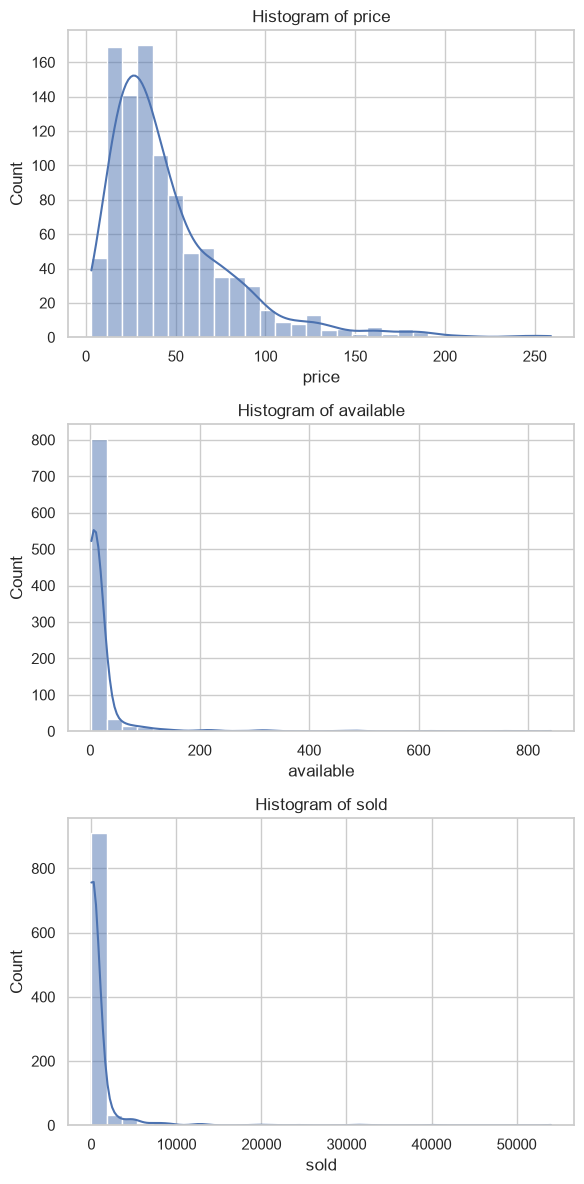

,feature,outliers_raw,outliers_after_log
0,price,54,5
1,available,101,89
2,sold,136,2


In [52]:
df = pd.read_csv('Sales-[5444].csv')
print("Dataset data overview")
display(df.head(10))


print("Dataset info overview")
display(df.info())

print("Missing values check")
display(df.isna().sum())

print("Duplicate values check")
display(df.duplicated().sum())

print("Summary statistics")
display(df.describe().T)

print("Understanding distribution of data")
numerical_columns = df.select_dtypes(include=['int64', 'float64']).columns.to_list()

fig, axes = plt.subplots(len(numerical_columns), 1, figsize=(6, 4 * len(numerical_columns)))
for i, column in enumerate(numerical_columns):
    sns.histplot(df[column], bins=30, kde=True, ax=axes[i])
    axes[i].set_title(f"Histogram of {column}")

plt.tight_layout()
plt.show()

# data is abnormally distributed so check for outlies using 1.5iqr
def detect_outliers(s, k=1.5):
    s = s.dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (s < q1 - k * iqr) | (s > q3 + k * iqr)

summary = []
for col in numerical_columns:
    s = df[col]
    log_s = np.log1p(s) if (s.dropna() > -1).all() else np.nan
    summary.append({
        'feature': col,
        'outliers_raw': detect_outliers(s).sum(),
        'outliers_after_log': detect_outliers(log_s).sum() if isinstance(log_s, pd.Series) else 'n/a (values <= -1)',
    })

pd.DataFrame(summary)

### Step 3: Data Preprocessing
The results above show that:
- the dataset contains missing values and outliers
- no duplicate data
- irrelevant columns (for the purpose of this project) and data in the wrong format such as the the `lastUpdated` field being of type string instead of text

The above stated will all be handled accordingly

In [53]:
# missing values

# 1. price an sold columns (recovering from already exisiting data)
# - price
df['currency'] = df['priceWithCurrency'].str.extract(r"^(\w+)\s*\$")[0]
price_with_currency = (df["priceWithCurrency"].str.extract(r"\$([\d,\.]+)")[0]
         .str.replace(",", "").astype(float))
df['price'] = df['price'].fillna(price_with_currency)

display(df.isna().sum())

# - sold - recovering from the text field
sold_text = (df["text"].str.extract(r"([\d,]+)\s+sold")[0]
              .str.replace(",", "").astype(float))
df['sold'] = df['sold'].fillna(sold_text)

display(df.isna().sum())

# 2. currency consistency - some rows are priced in canadian dollars
CAD_TO_USD = 0.73 # as of May 2024
df.loc[df['currency'] == 'C', 'price'] *= CAD_TO_USD

# 3. updating stock (available)
df.loc[df["text"].str.lower().str.startswith("last one", na=False), "available"] = 1

# Flags preserve information that imputation would erase
df["stock_censored"] = df["text"].str.contains("More than", na=False).astype(int)
df["stock_unknown"]  = df["available"].isna().astype(int)
df["available"] = df["available"].fillna(df["available"].median())

display(df)

# fix column data types
# - last updated column
df['lastUpdated'] =pd.to_datetime(
    df["lastUpdated"].str.replace(r"\s+P[DS]T$", "", regex=True),
    format="%b %d, %Y %H:%M:%S", errors="coerce")

snapshot = df['lastUpdated'].max()
df["days_since_update"] = (snapshot - df["lastUpdated"]).dt.total_seconds() / 86400
df["days_since_update"] = df["days_since_update"].fillna(df["days_since_update"].median())

# available and sold column - while these are discrete quantities, they cannot be converted to int because of the present of null values (np.NaN) which is of type float

# 4. normalizing the categories
print("Initial unique catergories")
display(df['Catatory'].unique())
df["Catatory"].value_counts()

def group_category(c):
    if pd.isna(c): return "Other"
    c = c.lower().strip()
    if "toil" in c or c == "edt":                                   return "EDT"
    if any(k in c for k in ["parfum", "perfume", "extrait", "elixir"]) or c == "edp":
        return "EDP/Parfum"
    if "cologne" in c or c in {"edc", "aftershave", "splash-on"}:   return "Cologne"
    return "Other"

df["Catatory"] = df["Catatory"].apply(group_category)
df["Catatory"].value_counts()

print("Normalized categories")
display(df['Catatory'].unique())

# 5. rename category column and remove whitespace
df.rename(columns={'Catatory': 'category'}, inplace=True)
display(df.columns)
df['category'] = df['category'].str.strip().str.title()

# 6. add bottle size feature
details = df["details"].str.replace(r"1/3\s*oz", "0.33 oz", regex=True, flags=re.I)
num = r"(\d*\.?\d+)"
oz = details.str.extract(num + r"\s*(?:fl\.?\s*)?(?:oz|ounce)", flags=re.I)[0].astype(float)
ml = details.str.extract(num + r"\s*ml", flags=re.I)[0].astype(float)
df["size_ml"] = ml.fillna(oz * 29.57)
df.loc[~df["size_ml"].between(0.5, 500), "size_ml"] = np.nan

# imputing
df["size_imputed"] = df["size_ml"].isna().astype(int)

df["size_ml"] = df["size_ml"].fillna(
    df.groupby("category")["size_ml"].transform("median")
)
df["size_ml"] = df["size_ml"].fillna(df["size_ml"].median()) 

df["price_per_ml"] = df["price"] / df["size_ml"]

print("Sizes imputed:", df["size_imputed"].sum())

display(df.columns)

# 7. drop rows with no sold quantity and add columns
display(df.shape)
df= df.dropna(subset=['sold'])
display(df.shape)
df['revenue'] = df['price'] * df['sold']

# 8. drop duplicates 
# No rowwise duplicates were found but they exist across a subset
print(df.duplicated(subset=["details", "Item_Name", "price", "category"]).sum())
df = df.drop_duplicates(subset=['details', 'Item_Name', 'price', 'category'])
print(df.duplicated(subset=["details", "Item_Name", "price", "category"]).sum())
print(df.shape)

# 9. handle outliers - all outliers are retained

# 10. drop irrelevant columns
irrelevant_columns = ['priceWithCurrency', 'Item_Name', 'text', 'details', 'lastUpdated', 'itemLocation', 'currency', 
                      'stock_censored', 'stock_unknown', 'days_since_update', 'price_per_ml', 'size_imputed', 'revenue']
feature_matrix = df.drop(columns=irrelevant_columns)
cleaned_df = df.drop(columns=['priceWithCurrency'])

# 10. final checks and modifications
print(cleaned_df.columns)
print(cleaned_df.isna().sum())
print(cleaned_df.duplicated().sum())
cleaned_df = cleaned_df.astype({'sold': int, 'available': int})

print(feature_matrix.columns)
print(feature_matrix.isnull().sum())
print(feature_matrix.duplicated().sum())
feature_matrix = feature_matrix.astype({'sold': int, 'available': int})

feature_matrix.drop_duplicates(inplace=True)
print(feature_matrix.duplicated().sum())

# 11 export cleaned datasets
cleaned_df.to_csv('cleaned_data/sales_data_cleaned.csv', index=False)
feature_matrix.to_csv('cleaned_data/feature_matrix.csv', index=False)


Item_Name              1
details                0
Catatory               3
price                  0
priceWithCurrency      1
available            111
text                   3
sold                   8
lastUpdated           53
itemLocation           0
currency               1
dtype: int64

Item_Name              1
details                0
Catatory               3
price                  0
priceWithCurrency      1
available            111
text                   3
sold                   6
lastUpdated           53
itemLocation           0
currency               1
dtype: int64

,Item_Name,details,Catatory,price,priceWithCurrency,available,text,sold,lastUpdated,itemLocation,currency,stock_censored,stock_unknown
0,Dior,Christian Dior Sauvage Men's EDP 3.4 oz Fragra...,Eau de Parfum,84.99,US $84.99/ea,10.0,More than 10 available / 116 sold,116.0,"May 24, 2024 10:03:04 PDT","Allen Park, Michigan, United States",US,1,0
1,AS SHOW,A-v-entus Eau de Parfum 3.3 oz 100ML Millesime...,Eau de Parfum,109.99,US $109.99,8.0,8 available / 48 sold,48.0,"May 23, 2024 23:07:49 PDT","Atlanta, Georgia, Canada",US,0,0
2,Unbranded,HOGO BOSS cologne For Men 3.4 oz,Eau de Toilette,100.00,US $100.00,10.0,More than 10 available / 27 sold,27.0,"May 22, 2024 21:55:43 PDT","Dearborn, Michigan, United States",US,1,0
3,Giorgio Armani,Acqua Di Gio by Giorgio Armani 6.7 Fl oz Eau D...,Eau de Toilette,44.99,US $44.99/ea,2.0,2 available / 159 sold,159.0,"May 24, 2024 03:30:43 PDT","Reinholds, Pennsylvania, United States",US,0,0
4,Lattafa,Lattafa Men's Hayaati Al Maleky EDP Spray 3.4 ...,Fragrances,16.91,NaN,9.0,Limited quantity available / 156 sold,156.0,"May 24, 2024 07:56:25 PDT","Brooklyn, New York, United States",NaN,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,GUESS,Guess 1981 by Guess cologne for men EDT 3.3 / ...,Eau de Toilette,20.28,US $20.28/ea,45.0,"45 available / 1,613 sold",1613.0,"May 24, 2024 08:14:07 PDT","Dallas, Texas, United States",US,0,0
996,Armaf,Club de Nuit Intense by Armaf cologne for men ...,Eau de Toilette,30.58,US $30.58,10.0,More than 10 available / 31 sold,31.0,"May 23, 2024 08:39:30 PDT",United States,US,1,0
997,Paco Rabanne,Invictus by Paco Rabanne for Men EDT Spray 3.4...,Eau de Toilette,39.99,US $39.99/ea,2.0,2 available / 305 sold,305.0,"May 23, 2024 15:27:18 PDT","Jamaica, New York, United States",US,0,0
998,Lomani,"Lomani EDT Cologne 3.4 oz Men - Authentic, Bra...",Eau de Toilette,9.99,US $9.99/ea,2.0,2 available / 22 sold,22.0,"May 20, 2024 13:20:54 PDT","Lincoln Park, Michigan, United States",US,0,0


Initial unique catergories


<StringArray>
[                                        'Eau de Parfum',
                                       'Eau de Toilette',
                                            'Fragrances',
                                               'Perfume',
                                                     '/',
                                                'PARFUM',
                                                'Parfum',
                      'Concentrated Uncut Pure Body Oil',
                                             'LE PARFUM',
                                         'Eau De Parfum',
                                                     nan,
                                             'Unscented',
                                        'Eau de Cologne',
                       '~ THE ONE EAU DE PARFUM SPRAY ~',
                                     'EXTRAIT DE PARFUM',
                                       'Eau De Toilette',
                                 'Eau De Parfum Intense',


Normalized categories


... (5 outputs left out)

(1000, 17)

(994, 17)

5
0
(989, 18)
Index(['Item_Name', 'details', 'category', 'price', 'available', 'text',
       'sold', 'lastUpdated', 'itemLocation', 'currency', 'stock_censored',
       'stock_unknown', 'days_since_update', 'size_ml', 'size_imputed',
       'price_per_ml', 'revenue'],
      dtype='str')
Item_Name             1
details               0
category              0
price                 0
available             0
text                  0
sold                  0
lastUpdated          47
itemLocation          0
currency              1
stock_censored        0
stock_unknown         0
days_since_update     0
size_ml               0
size_imputed          0
price_per_ml          0
revenue               0
dtype: int64
0
Index(['category', 'price', 'available', 'sold', 'size_ml'], dtype='str')
category     0
price        0
available    0
sold         0
size_ml      0
dtype: int64
1
0


/var/folders/4z/34wnx7d50k586tbjblkfp1w40000gn/T/ipykernel_62944/996384474.py:124: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  feature_matrix.drop_duplicates(inplace=True)


### Step 4: Feature Matrix Transformation

,category,price,available,sold,size_ml
0,Edp/Parfum,84.99,10,116,100.538
1,Edp/Parfum,109.99,8,48,100.000
2,Edt,100.00,10,27,100.538
3,Edt,44.99,2,159,198.119
4,Other,16.91,9,156,100.538


Missing values count: 0
Duplicate values count: 0
Column types: category         str
price        float64
available      int64
sold           int64
size_ml      float64
dtype: object Dataset shape: (988, 5)
Outliers check


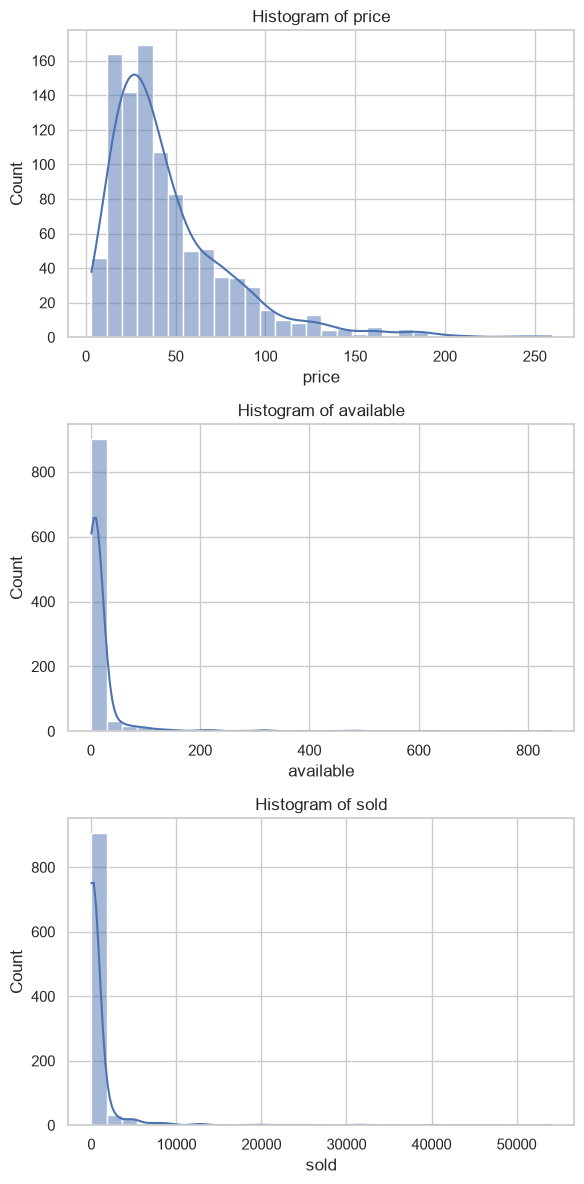

,feature,outliers_raw,outliers_after_log
0,price,52,4
1,available,98,80
2,sold,136,2


In [54]:
df = pd.read_csv('cleaned_data/feature_matrix.csv')
# data receck
display(df.head())
print(
    f"Missing values count: {df.isna().sum().sum()}\n"
    f"Duplicate values count: {df.duplicated().sum().sum()}\n"
    f"Column types: {df.dtypes}",
    f"Dataset shape: {df.shape}"
)

print("Outliers check")
numerical_columns = df.select_dtypes(include=['int64', 'float64']).columns.to_list()
numerical_columns.pop(-1)

fig, axes = plt.subplots(len(numerical_columns), 1, figsize=(6, 4 * len(numerical_columns)))
for i, column in enumerate(numerical_columns):
    sns.histplot(df[column], bins=30, kde=True, ax=axes[i])
    axes[i].set_title(f"Histogram of {column}")

plt.tight_layout()
plt.show()

# data is abnormally distributed so check for outlies using 1.5iqr
def detect_outliers(s, k=1.5):
    s = s.dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (s < q1 - k * iqr) | (s > q3 + k * iqr)

summary = []
for col in numerical_columns:
    s = df[col]
    log_s = np.log1p(s) if (s.dropna() > -1).all() else np.nan
    summary.append({
        'feature': col,
        'outliers_raw': detect_outliers(s).sum(),
        'outliers_after_log': detect_outliers(log_s).sum() if isinstance(log_s, pd.Series) else 'n/a (values <= -1)',
    })

display(pd.DataFrame(summary))

In [55]:
# 1. log transform for handling skew
log_cols = numerical_columns # size_ml is not included as it is symmetric - the result below demonstrates it
skew_check = pd.DataFrame({
    'skew_raw': df[log_cols + ['size_ml']].skew(),
    'skew_log1p': np.log1p(df[log_cols + ['size_ml']]).skew(),
}).round(2)
display(skew_check)

df_log = df.copy()
df_log[log_cols] = np.log1p(df[log_cols])
display(df_log.head())

# 2. Scaling and encoding
numeric_cols = df.columns[1:]

scaler = StandardScaler()
X_numeric = pd.DataFrame(
    scaler.fit_transform(df_log[numeric_cols]),
    columns=numeric_cols,
    index=df_log.index
)

X_category = pd.get_dummies(df_log['category'], prefix='category', dtype=int)

X = pd.concat([X_numeric, X_category], axis=1)
print(f"Model input shape: {X.shape}")
display(X.head())
display(X.describe().T.round(2))

# 3. pca


,skew_raw,skew_log1p
price,1.97,0.08
available,8.60,1.58
sold,9.70,0.53
size_ml,0.05,-2.85


,category,price,available,sold,size_ml
0,Edp/Parfum,4.454231,2.397895,4.762174,100.538
1,Edp/Parfum,4.709440,2.197225,3.891820,100.000
2,Edt,4.615121,2.397895,3.332205,100.538
3,Edt,3.828424,1.098612,5.075174,198.119
4,Other,2.885359,2.302585,5.056246,100.538


Model input shape: (988, 8)


,price,available,sold,size_ml,category_Cologne,category_Edp/Parfum,category_Edt,category_Other
0,1.233757,0.201774,0.220586,0.050389,0,1,0,0
1,1.615705,-0.017025,-0.199978,0.037332,0,1,0,0
2,1.474545,0.201774,-0.470391,0.050389,0,0,1,0
3,0.297169,-1.214888,0.371831,2.418702,0,0,1,0
4,-1.114229,0.097854,0.362685,0.050389,0,0,0,1


,count,mean,std,min,25%,50%,75%,max
price,988.0,-0.00,1.00,-3.36,-0.68,-0.03,0.69,2.89
available,988.0,0.00,1.00,-1.66,-0.66,0.10,0.20,4.93
sold,988.0,0.00,1.00,-1.75,-0.77,-0.18,0.72,3.19
size_ml,988.0,-0.00,1.00,-2.37,0.04,0.05,0.05,3.35
category_Cologne,988.0,0.07,0.26,0.00,0.00,0.00,0.00,1.00
category_Edp/Parfum,988.0,0.39,0.49,0.00,0.00,0.00,1.00,1.00
category_Edt,988.0,0.47,0.50,0.00,0.00,0.00,1.00,1.00
category_Other,988.0,0.07,0.25,0.00,0.00,0.00,0.00,1.00


### Step 4: Model Training and Evaluation

#### 1. K-Means

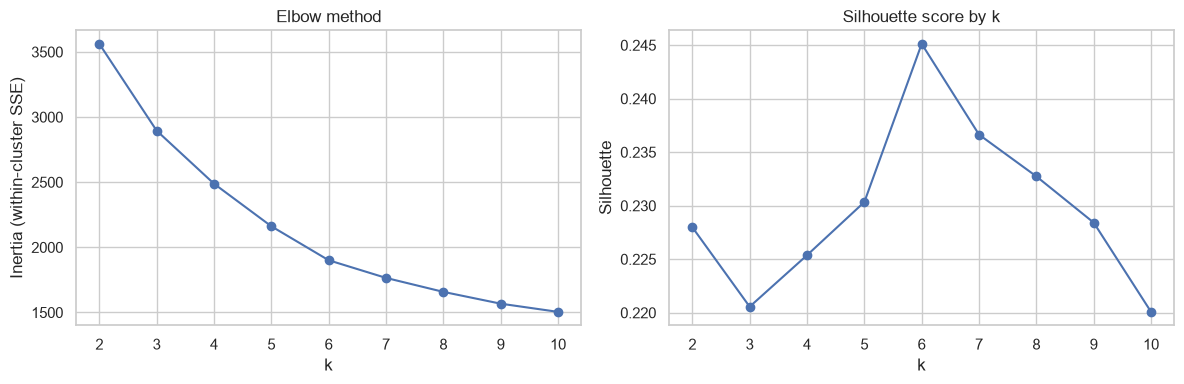

In [56]:
k_range = range(2, 11)
inertias, sil_scores = [], []

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = kmeans.fit_predict(X)
    inertias.append(kmeans.inertia_)
    sil_scores.append(silhouette_score(X, labels))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(k_range, inertias, marker='o')
axes[0].set(title='Elbow method', xlabel='k', ylabel='Inertia (within-cluster SSE)')
axes[1].plot(k_range, sil_scores, marker='o')
axes[1].set(title='Silhouette score by k', xlabel='k', ylabel='Silhouette')
plt.tight_layout()
plt.show()

best_k = 4
kmeans = KMeans(n_clusters=best_k, random_state=RANDOM_STATE, n_init=10)
kmeans_labels = kmeans.fit_predict(X)

### 2. Hierachical Clustering (Agglomerative)

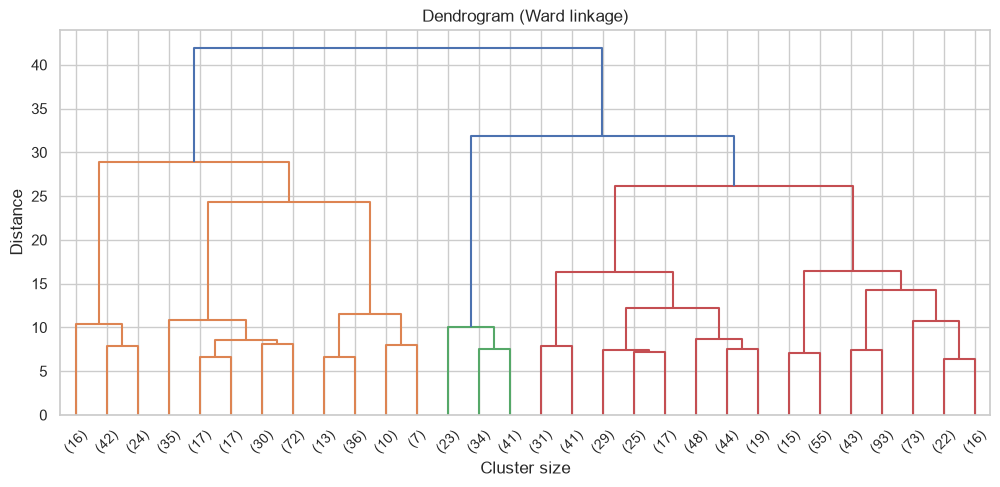

2     0.211
3     0.212
4     0.217
5     0.177
6     0.195
7     0.181
8     0.178
9     0.179
10    0.190
Name: silhouette, dtype: float64

In [57]:
plt.figure(figsize=(12, 5))
dendrogram(linkage(X, method='ward'), truncate_mode='lastp', p=30)
plt.title('Dendrogram (Ward linkage)')
plt.xlabel('Cluster size')
plt.ylabel('Distance')
plt.show()

hier_sil = {k: silhouette_score(X, AgglomerativeClustering(n_clusters=k, linkage='ward').fit_predict(X))
            for k in range(2, 11)}
display(pd.Series(hier_sil, name='silhouette').round(3))

best_k_hier = 4
hier = AgglomerativeClustering(n_clusters=best_k_hier, linkage='ward')
hier_labels = hier.fit_predict(X)

#### 3. DBSCAN

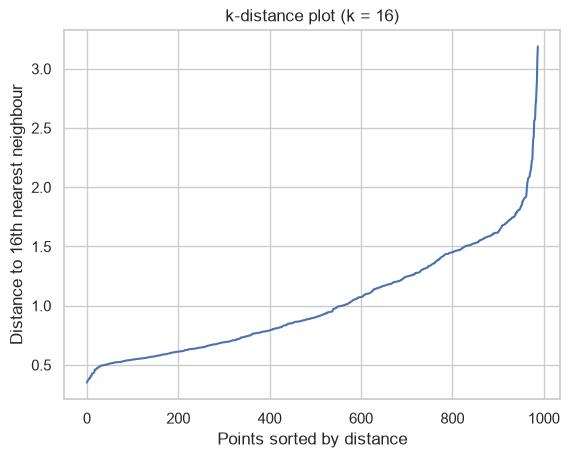

eps=0.6: clusters=2, noise points=619
eps=0.8: clusters=4, noise points=385
eps=1.0: clusters=4, noise points=269
eps=1.2: clusters=4, noise points=164


In [58]:
min_samples = 2 * X.shape[1]
distances, _ = NearestNeighbors(n_neighbors=min_samples).fit(X).kneighbors(X)
k_dist = np.sort(distances[:, -1])

plt.plot(k_dist)
plt.title(f'k-distance plot (k = {min_samples})')
plt.xlabel('Points sorted by distance')
plt.ylabel(f'Distance to {min_samples}th nearest neighbour')
plt.show()

# try a few eps values around the elbow
for eps in [0.6, 0.8, 1.0, 1.2]:
    labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X)
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    print(f"eps={eps}: clusters={n_clusters}, noise points={(labels == -1).sum()}")

best_eps = 1.0  # set from the plot and results above
dbscan_labels = DBSCAN(eps=best_eps, min_samples=min_samples).fit_predict(X)

### Comparison and Evaluation

In [59]:
def evaluate(X, labels, name):
    mask = labels != -1  # exclude DBSCAN noise points from the metrics
    return {
        'model': name,
        'n_clusters': len(set(labels[mask])),
        'noise_points': (~mask).sum(),
        'silhouette': silhouette_score(X[mask], labels[mask]),
        'davies_bouldin': davies_bouldin_score(X[mask], labels[mask]),
        'calinski_harabasz': calinski_harabasz_score(X[mask], labels[mask]),
    }

comparison = pd.DataFrame([
    evaluate(X, kmeans_labels, 'K-Means'),
    evaluate(X, hier_labels, 'Hierarchical (Ward)'),
    evaluate(X, dbscan_labels, 'DBSCAN'),
]).round(3)
display(comparison)

,model,n_clusters,noise_points,silhouette,davies_bouldin,calinski_harabasz
0,K-Means,4,0,0.225,1.393,273.563
1,Hierarchical (Ward),4,0,0.217,1.515,214.215
2,DBSCAN,4,269,0.218,1.263,130.633
